# **Lab. 12 — Classificação de imagens de satélite com CNN (EuroSAT)**

Objetivo: Desenvolver e avaliar uma rede neural convolucional (CNN) própria para classificar imagens coloridas em múltiplos classes, justificando de forma crítica a escolha do conjunto de dados.

## **1. Escolha do dataset**

Escolhi o EuroSAT (versão RGB) com exatas 27.000 imagens de satélite (missão Sentinel-2, do programa europeu
Copernicus) de 64×64 pixels, rotuladas em 10 classes de uso e cobertura do solo:
- *AnnualCrop* (lavoura anual)
- *Forest* (floresta)
- *HerbaceousVegetation* (vegetação herbácea)
- *Highway* (rodovia)
- *Industrial* (área industrial)
- *Pasture* (pasto)
- *PermanentCrop* (cultivo permanente)
- *Residential* (área residencial)
- *River* (rio)
- *SeaLake* (mar/lago)

### **1.1. Complexidade**
Imagens de sensoriamento remoto em que a visão é feita de cima, sem "frente" nem "fundo" e com texturas muito diferentes das fotos do dia a dia. Imagens coloridas (RGB) de baixa resolução, e várias classes são visualmente parecidas (*Highway* × *River*; *AnnualCrop* × *PermanentCrop* × *Pasture* × *HerbaceousVegetation*). É bem mais difícil que o MNIST, mas o tamanho pequeno (64×64) e as ~27 mil imagens permitem treinar uma CNN do zero em poucos minutos na GPU.

### **1.2. Confiança na fonte**
Publicado pelos autores do dataset (Helber et al., 2019, *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing*), muito usado como *benchmark* de classificação de uso do solo, e hospedado no Zenodo sob **licença MIT**.

As imagens vêm de uma missão de observação da Terra de uma agência pública, e não de coleta aleatória na web. Os rótulos foram atribuídos pelos autores, e como cada imagem é um recorte pequeno, algumas contêm mais de um tipo de cobertura.

### **1.3. Motivação**
Classificar o uso do solo automaticamente serve para monitoramento ambiental (desmatamento, avanço da agricultura), planejamento urbano e gestão de recursos hídricos, em larga escala, sem depender de levantamento manual.

### **1.4. Balanceamento**
As classes têm entre cerca de 2.000 e 3.000 imagens (a razão entre a maior e a menor se aproxima de 1,5; o gráfico da próxima seção mostra os números reais). Não é crítico, mas por isso usei divisão estratificada e olhei o Precision/Recall/F1 por classe e a média *macro*, não só a acurácia.

### **1.5. Limitações**  
As imagens cobrem regiões da Europa, então o modelo pode não generalizar para outros contextos (por exemplo, vegetação, cultivos e construções típicos do Brasil). A resolução de 64×64 limita os detalhes visíveis, e a visão RGB não usa as bandas infravermelhas, que ajudariam a separar vegetação.

## **2. Importações**


In [ ]:
import time
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import set_random_seed

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support, accuracy_score)

set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU disponivel:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponivel: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
import zipfile
import shutil
from pathlib import Path

# 1. Define caminhos principais
pasta_pasture = Path('/content/Pasture')
zip_path = Path('/content/EuroSAT_RGB.zip')

# 2. Extrai o arquivo ZIP já presente diretamente na raiz /content
raiz_dir = Path('/content')
if zip_path.exists():
    print(f"Extraindo o arquivo {zip_path.name}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(raiz_dir)
    print(f"Conteúdo extraído com sucesso na pasta raiz: {raiz_dir}!")
else:
    print(f"Erro: O arquivo {zip_path} não foi encontrado no ambiente. Verifique o upload.")

Extraindo o arquivo EuroSAT_RGB.zip...
Conteúdo extraído com sucesso na pasta raiz: /content!


## **3. Carregar e conhecer os dados**

Baixei e extraí o arquivo `EuroSAT_RGB.zip` (cerca de 95 MB) do Zenodo. Cada subpasta representa uma classe.

Em vez de carregar todas as imagens na memória de uma vez, guardei os caminhos dos arquivos e os
rótulos (de 0 a 9). Isso permitiu fazer a divisão treino/validação/teste de forma
estratificada antes de abrir as imagens.

O código descobre as classes pelo nome da pasta de cada imagem, então não depende da estrutura exata do zip.

In [9]:
import pathlib
import numpy as np

# Como o ZIP já foi extraído na raiz, apontar diretamente para a pasta de dados extraída
# O dataset EuroSAT costuma extrair os dados em uma pasta chamada '2750' ou similar dentro de '/content'
base_dir = pathlib.Path('/content/2750')

# Caso a estrutura extraída seja diferente, tenta procurar a pasta correta
if not base_dir.exists():
    # Busca qualquer subpasta contendo as classes na raiz
    pastas_possiveis = [p for p in pathlib.Path('/content').iterdir() if p.is_dir() and (p / 'Forest').exists()]
    if pastas_possiveis:
        base_dir = pastas_possiveis[0]
    else:
        base_dir = pathlib.Path('/content')

print(f"Usando o diretório de dados: {base_dir}")

# Acha todas as imagens; a pasta de cada uma e o nome da classe
arquivos = sorted(p for p in base_dir.rglob("*") if p.suffix.lower() in (".jpg", ".jpeg"))
nomes = [p.parent.name for p in arquivos]
class_names = sorted(set(nomes))
num_classes = len(class_names)
indice = {nome: i for i, nome in enumerate(class_names)}

paths = np.array([str(p) for p in arquivos])
labels = np.array([indice[n] for n in nomes])

print("Classes:", class_names)
print("Total de imagens:", len(paths))

Usando o diretório de dados: /content/EuroSAT_RGB
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Total de imagens: 27000


AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Highway                 2500
Industrial              2500
Pasture                 2000
PermanentCrop           2500
Residential             3000
River                   2500
SeaLake                 3000
dtype: int64

Razao maior/menor classe: 1.50


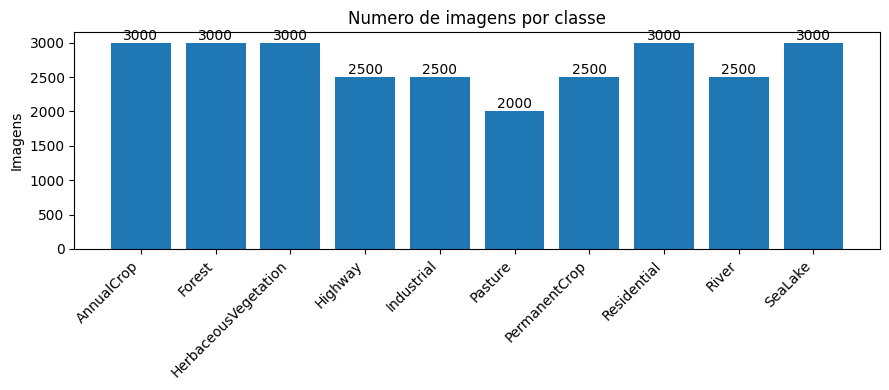

In [10]:
# Balanceamento das classes
contagem = pd.Series(np.bincount(labels), index=class_names)
print(contagem)
print(f"\nRazao maior/menor classe: {contagem.max() / contagem.min():.2f}")

plt.figure(figsize=(9, 4))
barras = plt.bar(class_names, contagem.values, color="tab:blue")
plt.bar_label(barras)
plt.xticks(rotation=45, ha="right")
plt.title("Numero de imagens por classe")
plt.ylabel("Imagens")
plt.tight_layout(); plt.show()

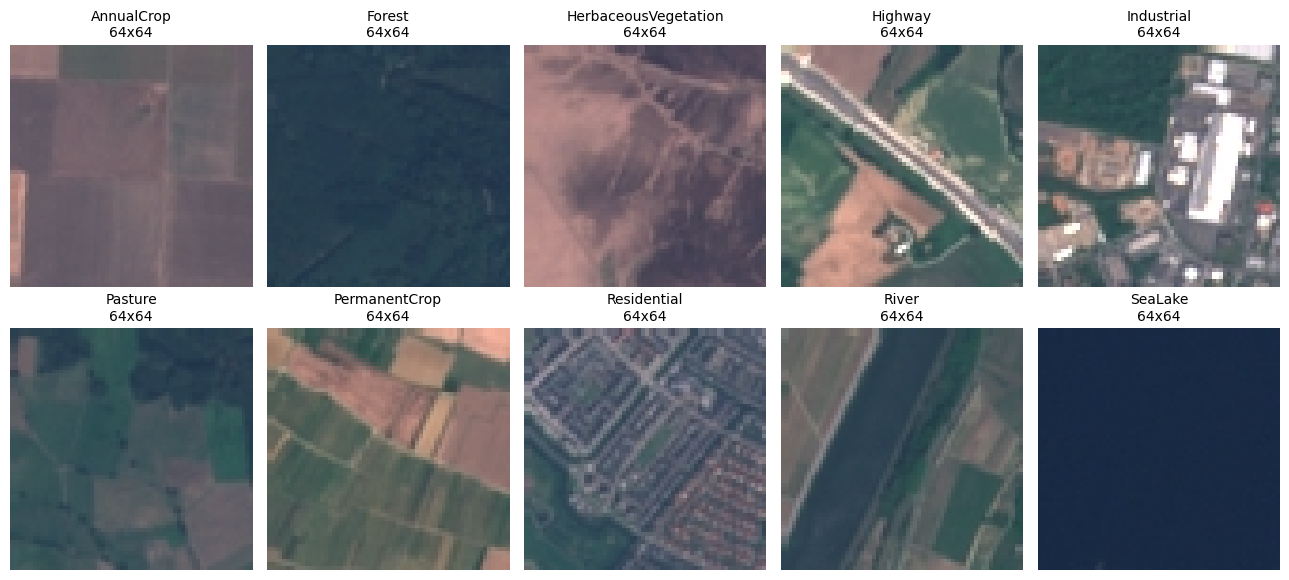

In [11]:
# Uma imagem de cada classe (64x64, RGB)
colunas = (num_classes + 1) // 2
plt.figure(figsize=(2.6 * colunas, 6))
for i, cls in enumerate(class_names):
    img = plt.imread(paths[np.where(labels == i)[0][0]])
    plt.subplot(2, colunas, i + 1)
    plt.imshow(img)
    plt.title(f"{cls}\n{img.shape[1]}x{img.shape[0]}", fontsize=10)
    plt.axis("off")
plt.tight_layout(); plt.show()

## **4. Divisão em treino, validação e teste**

Usei a proporção **70% treino / 15% validação / 15% teste**, de forma estratificada
(`stratify=labels`), assim cada conjunto mantém a mesma proporção de cada classe do dataset original.

- **Treino:** a rede ajusta os pesos com estes dados.
- **Validação:** usada *durante* o treino para acompanhar o overfitting, ajustar a taxa de aprendizado e decidir quando parar. Também é a base para comparar topologias.
- **Teste:** fica intocado até a avaliação final. Só ele dá uma estimativa honesta do desempenho em imagens novas.

In [13]:
# 1) separa 70% para treino e 30% para "resto"
paths_train, paths_tmp, y_train, y_tmp = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=42)

# 2) divide o "resto" ao meio: 15% validacao e 15% teste
paths_val, paths_test, y_val, y_test = train_test_split(
    paths_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

total = len(paths)
for nome, y in [("Treino", y_train), ("Validacao", y_val), ("Teste", y_test)]:
    print(f"{nome:10s}: {len(y):5d} imagens ({len(y) / total * 100:.1f}%)")
print("\nImagens por classe (treino):", np.bincount(y_train))
print("Imagens por classe (teste): ", np.bincount(y_test))

Treino    : 18900 imagens (70.0%)
Validacao :  4050 imagens (15.0%)
Teste     :  4050 imagens (15.0%)

Imagens por classe (treino): [2100 2100 2100 1750 1750 1400 1750 2100 1750 2100]
Imagens por classe (teste):  [450 450 450 375 375 300 375 450 375 450]


## **5. Pré-processamento**

### **5.1. Redimensionamento**
A CNN precisa de entradas do mesmo tamanho. As imagens do EuroSAT já têm 64 × 64 × 3 (3 canais = RGB), então o redimensionamento é um passo de segurança que não altera nada aqui. Manter esse passo no pipeline deixa o código reutilizável para outros datasets.

### **5.2. Normalização**
Os pixels vão de 0 a 255. A divisão por 255 é feita dentro do modelo, com uma camada
   `Rescaling(1/255)`. Assim a mesma escala vale no treino, na validação, no teste e em imagens novas.
### **5.3. Data augmentation** (apenas para treino)
Giros horizontais e verticais, pequenas rotações e zoom aleatórios. Em imagens de satélite, não existe "lado de cima" nem "lado de baixo", então os giros verticais são variações realistas. Essas camadas ficam inativas na validação, no teste e na predição.

### **5.4. Pipeline `tf.data`**
Lê os arquivos, decodifica o JPEG, embaralha só o treino, agrupa em lotes e usa
   `prefetch` para a GPU não esperar o disco. O `cache` (opcional) guarda as imagens decodificadas como `uint8`
   na memória (cerca de 330 MB para o dataset todo); se faltar memória, colocar `USAR_CACHE = False`.

In [15]:
IMG_SIZE = 64
BATCH_SIZE = 64
USAR_CACHE = True      # coloque False se faltar memoria (o treino fica um pouco mais lento)
AUTOTUNE = tf.data.AUTOTUNE

def carregar_imagem(caminho, rotulo):
    img = tf.io.read_file(caminho)
    img = tf.image.decode_jpeg(img, channels=3)          # garante 3 canais (RGB)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))     # redimensiona (aqui ja sao 64x64)
    img = tf.cast(img, tf.uint8)                         # guarda como uint8 (0-255) para poupar memoria
    return img, rotulo

def criar_dataset(caminhos, rotulos, treino=False):
    ds = tf.data.Dataset.from_tensor_slices((caminhos, rotulos))
    ds = ds.map(carregar_imagem, num_parallel_calls=AUTOTUNE)
    if USAR_CACHE:
        ds = ds.cache()                                  # le do disco so na 1a epoca
    if treino:
        ds = ds.shuffle(2000, seed=42)                 # embaralha a cada epoca (so no treino)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = criar_dataset(paths_train, y_train, treino=True)
val_ds   = criar_dataset(paths_val,   y_val)
test_ds  = criar_dataset(paths_test,  y_test)             # sem shuffle: a ordem bate com y_test

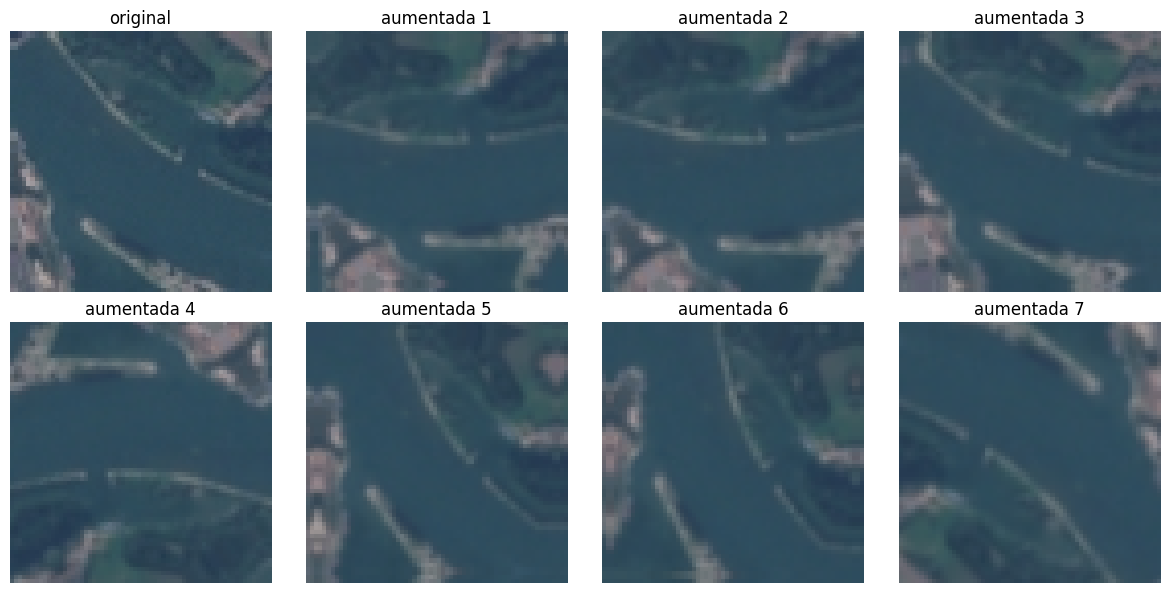

In [16]:
# Camadas de data augmentation (ativas somente quando training=True)
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

# Visualizacao: a mesma imagem de treino com 7 variacoes aleatorias
img_exemplo, _ = next(iter(train_ds.unbatch().take(1)))
plt.figure(figsize=(12, 6))
plt.subplot(2, 4, 1)
plt.imshow(img_exemplo.numpy()); plt.title("original"); plt.axis("off")
for i in range(7):
    aug = data_augmentation(tf.expand_dims(tf.cast(img_exemplo, tf.float32), 0), training=True)
    plt.subplot(2, 4, i + 2)
    plt.imshow(aug[0].numpy().astype("uint8")); plt.title(f"aumentada {i + 1}"); plt.axis("off")
plt.tight_layout(); plt.show()

## **6. Arquitetura da CNN**

A rede é montada por uma função `build_cnn(...)`, que recebe o número de filtros de cada bloco, o tamanho da camada densa, a taxa de dropout e se usa BatchNorm.

**Arquitetura-base** (`filters=(32, 64, 128)`)

| Camada | Papel |
| --- | --- |
| `Input(64,64,3)` | Entrada: imagem RGB de satélite. |
| `Rescaling(1/255)` | Normaliza os pixels para 0–1. |
| `data_augmentation` | Giros, rotação e zoom aleatórios (só no treino). |
| **Bloco convolucional** × 3: `Conv2D(f, 3×3, padding="same")` → `BatchNormalization` → `ReLU` → `MaxPooling2D(2×2)` | A **convolução** aprende filtros que detectam características (bordas, cores, texturas); com mais blocos, as características ficam mais abstratas (de bordas e manchas de cor a padrões como o traçado de uma rodovia ou a textura de uma lavoura). A **BatchNorm** normaliza as ativações de cada lote, o que estabiliza e acelera o treino. A **ReLU** adiciona não linearidade. O **pooling** reduz a resolução pela metade (64 → 32 → 16 → 8) e dá tolerância a pequenos deslocamentos. O número de filtros dobra a cada bloco (32 → 64 → 128): a resolução cai, então podemos aumentar a "largura" da rede. |
| `GlobalAveragePooling2D` | Faz a média de cada mapa de características, gerando um vetor com um valor por filtro (128). Substitui o `Flatten` e tem **muito menos parâmetros** (um `Flatten` aqui geraria 8×8×128 = 8.192 valores, o que favoreceria o overfitting). |
| `Dropout(0.4)` | Desliga 40% dos neurônios aleatoriamente no treino (**regularização**). |
| `Dense(128, ReLU)` | Camada totalmente conectada que combina as características. |
| `Dropout(0.4)` | Mais regularização antes da saída. |
| `Dense(10, softmax)` | **Saída**: uma probabilidade por classe (somam 1). |

> Com `padding="same"`, a convolução mantém a resolução, e só o pooling a reduz. Isso difere do `padding="valid"` visto no MNIST (28 → 26).

In [18]:
def build_cnn(filters=(32, 64, 128), dense_units=128, dropout=0.4,
              batch_norm=True, augmentation=True, name="cnn"):
    entrada = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1.0 / 255)(entrada)             # 0-255 -> 0-1
    if augmentation:
        x = data_augmentation(x)                         # so atua no treino

    # Um bloco convolucional por valor em 'filters'
    for f in filters:
        x = layers.Conv2D(f, (3, 3), padding="same", use_bias=not batch_norm)(x)
        if batch_norm:
            x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D((2, 2))(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    saida = layers.Dense(num_classes, activation="softmax")(x)
    return models.Model(entrada, saida, name=name)

set_random_seed(42)
model = build_cnn(name="cnn_base")
model.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,722 (436.41 KB)

 Trainable params: 111,274 (434.66 KB)

 Non-trainable params: 448 (1.75 KB)

## **7. Hiperparâmetros e treinamento**

| Hiperparâmetro | Valor | Observação |
| --- | --- | --- |
| **Otimizador** | Adam | Taxa de aprendizado adaptativa por parâmetro; funciona bem sem muito ajuste. |
| **Taxa de aprendizado** | 0,001 (inicial) | O `ReduceLROnPlateau` reduz pela metade se a `val_loss` não melhorar por 3 épocas (mínimo 1e-5). |
| **Função de perda** | `sparse_categorical_crossentropy` | Equivale à *categorical crossentropy* da aula, mas aceita rótulos inteiros (0–9) em vez de one-hot. |
| **Tamanho do lote** | 64 | Imagens processadas por passo de atualização dos pesos. |
| **Épocas** | até 30 | Com `EarlyStopping` (paciência 6 sobre `val_loss`, restaurando os melhores pesos), então o treino pode terminar antes. |
| **Regularização** | Dropout 0,4 · BatchNorm · data augmentation · EarlyStopping | Combate o overfitting. |
| **Métrica acompanhada** | acurácia | Na avaliação final usamos também Precision, Recall e F1. |

In [19]:
EPOCHS = 30
LEARNING_RATE = 1e-3

def compilar(modelo, lr=LEARNING_RATE):
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

def treinar(modelo, epocas, verbose=1):
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    return modelo.fit(train_ds, validation_data=val_ds, epochs=epocas,
                      callbacks=callbacks, verbose=verbose)

compilar(model)
history = treinar(model, EPOCHS)

Epoch 1/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.5393 - loss: 1.2979 - val_accuracy: 0.2072 - val_loss: 2.5350 - learning_rate: 0.0010
Epoch 2/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.6620 - loss: 0.9534 - val_accuracy: 0.5005 - val_loss: 1.4518 - learning_rate: 0.0010
Epoch 3/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.7040 - loss: 0.8397 - val_accuracy: 0.6052 - val_loss: 1.1553 - learning_rate: 0.0010
Epoch 4/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.7269 - loss: 0.7778 - val_accuracy: 0.6474 - val_loss: 1.0113 - learning_rate: 0.0010
Epoch 5/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.7492 - loss: 0.7203 - val_accuracy: 0.6114 - val_loss: 1.1326 - learning_rate: 0.0010
Epoch 6/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7606 - loss: 0.6894 - val_accuracy: 0.5775 - val_loss: 1.4967 - learning_rate: 0.0010
Epoch 7/30
296/296 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.7657 - loss: 

## **8. Curvas de aprendizado (acurácia e erro)**

Mostra-se treino × validação para acurácia e perda (*loss*, o "erro"). A linha tracejada marca a época com a menor `val_loss`, cujos pesos o `EarlyStopping` restaurou.

O ideal é treino e validação andarem juntos.

Sinais de overfitting: a acurácia de treino continua subindo enquanto a de validação estaciona, e a `val_loss` para de cair e começa a subir. Como o treino usa augmentation e dropout, é normal a acurácia de treino ficar abaixo da de validação nas primeiras epochs.

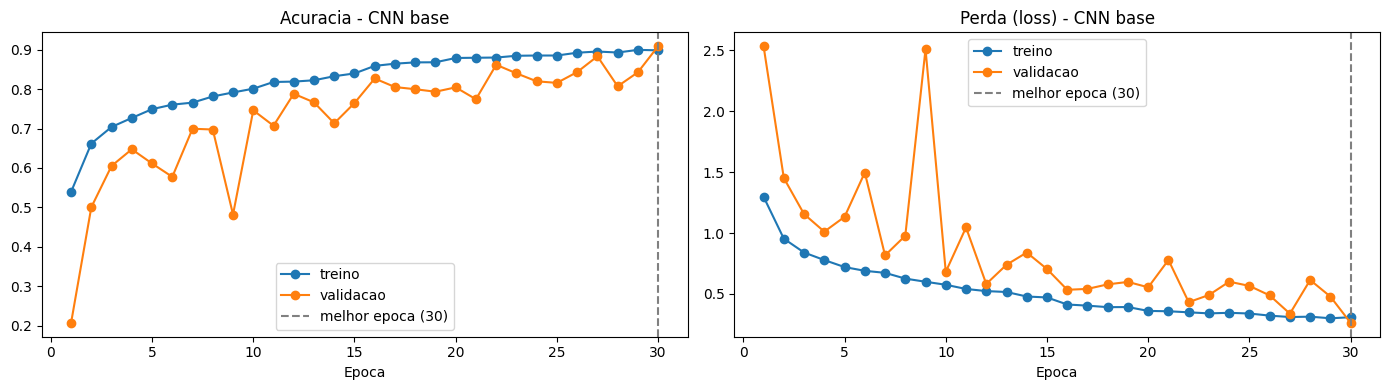

In [20]:
def plotar_curvas(history, titulo=""):
    h = history.history
    epocas = range(1, len(h["loss"]) + 1)
    melhor = int(np.argmin(h["val_loss"])) + 1
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    ax[0].plot(epocas, h["accuracy"], marker="o", label="treino")
    ax[0].plot(epocas, h["val_accuracy"], marker="o", label="validacao")
    ax[0].axvline(melhor, ls="--", color="gray", label=f"melhor epoca ({melhor})")
    ax[0].set_title("Acuracia " + titulo); ax[0].set_xlabel("Epoca"); ax[0].legend()

    ax[1].plot(epocas, h["loss"], marker="o", label="treino")
    ax[1].plot(epocas, h["val_loss"], marker="o", label="validacao")
    ax[1].axvline(melhor, ls="--", color="gray", label=f"melhor epoca ({melhor})")
    ax[1].set_title("Perda (loss) " + titulo); ax[1].set_xlabel("Epoca"); ax[1].legend()

    plt.tight_layout(); plt.show()

plotar_curvas(history, "- CNN base")

## 9. Avaliação no conjunto de teste

Agora o conjunto de teste (que a rede nunca viu). Além da acurácia, é calculado:

- **Precision (precisão):** das imagens que a rede disse ser da classe X, quantas realmente eram? (evita falsos positivos)
- **Recall (revocação):** de todas as imagens que eram da classe X, quantas a rede encontrou? (evita falsos negativos)
- **F1-Score:** média harmônica de Precision e Recall; resume os dois em um número.
- **Média macro:** média simples entre as classes, sem ponderar pelo tamanho. É a mais sensível ao desempenho nas classes menores (importante em um dataset levemente desbalanceado).
- **Matriz de confusão:** mostra *onde* a rede erra (linhas = classe real, colunas = classe prevista).

In [21]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Perda no teste: {test_loss:.4f}  |  Acuracia no teste: {test_acc * 100:.2f}%\n")

probs = model.predict(test_ds, verbose=0)    # (n_teste, 10) probabilidades
y_pred = probs.argmax(axis=1)                # classe prevista = indice da maior probabilidade

print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

Perda no teste: 0.2651  |  Acuracia no teste: 90.67%

                      precision    recall  f1-score   support

          AnnualCrop      0.939     0.860     0.898       450
              Forest      0.974     0.982     0.978       450
HerbaceousVegetation      0.914     0.853     0.883       450
             Highway      0.952     0.795     0.866       375
          Industrial      0.944     0.899     0.921       375
             Pasture      0.903     0.963     0.932       300
       PermanentCrop      0.904     0.803     0.850       375
         Residential      0.829     0.991     0.903       450
               River      0.762     0.955     0.847       375
             SeaLake      0.993     0.956     0.974       450

            accuracy                          0.907      4050
           macro avg      0.911     0.906     0.905      4050
        weighted avg      0.913     0.907     0.907      4050



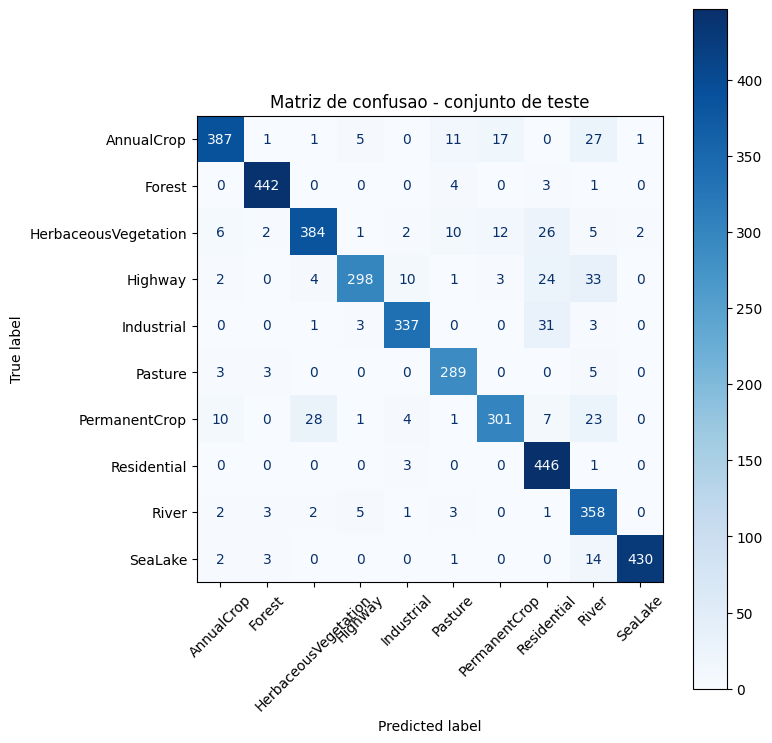

In [22]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", xticks_rotation=45)
ax.set_title("Matriz de confusao - conjunto de teste")
plt.tight_layout(); plt.show()

## 10. Imagens do teste: predição × real

Título verde = acerto

Título vermelho = erro

O percentual é a confiança (probabilidade da classe prevista).
Primeiro, 12 imagens sorteadas; depois, os erros da rede, para entender o que a confunde.

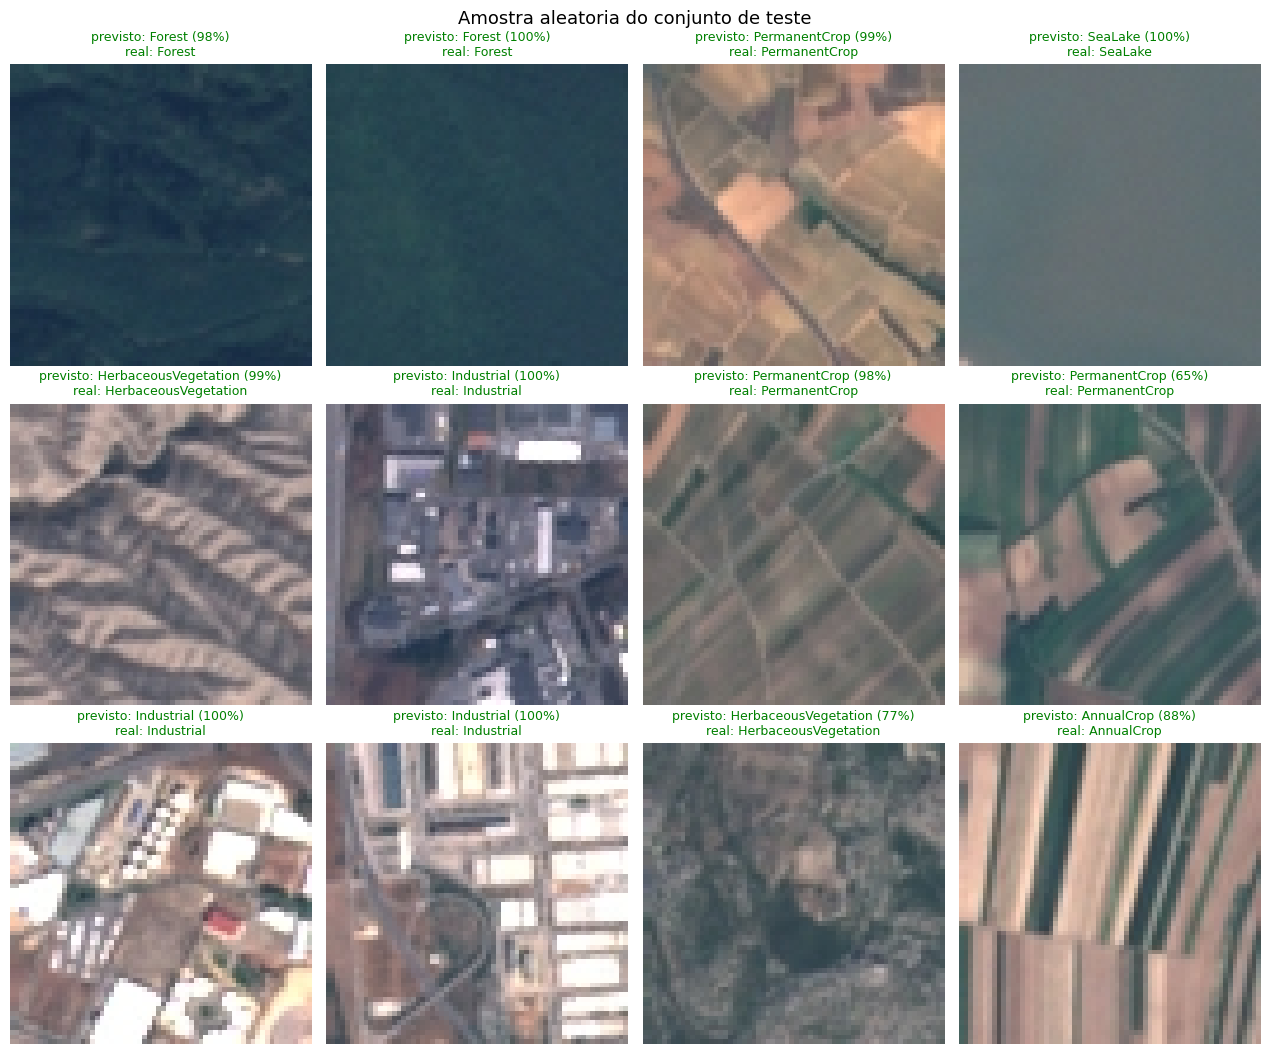

In [24]:
# Junta todas as imagens do teste em um array (uint8 de 64x64x3)
x_test_imgs = np.concatenate([x.numpy() for x, _ in test_ds])

def mostrar_grade(indices, titulo, linhas, colunas):
    fig, axes = plt.subplots(linhas, colunas, figsize=(3.2 * colunas, 3.6 * linhas))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, i in zip(np.ravel(axes), indices):
        ax.imshow(x_test_imgs[i])
        acertou = y_pred[i] == y_test[i]
        ax.set_title(f"previsto: {class_names[y_pred[i]]} ({probs[i].max() * 100:.0f}%)\n"
                     f"real: {class_names[y_test[i]]}",
                     color="green" if acertou else "red", fontsize=9)
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(42)
sorteadas = rng.choice(len(y_test), size=12, replace=False)
mostrar_grade(sorteadas, "Amostra aleatoria do conjunto de teste", 3, 4)

A rede errou 378 de 4050 imagens de teste.


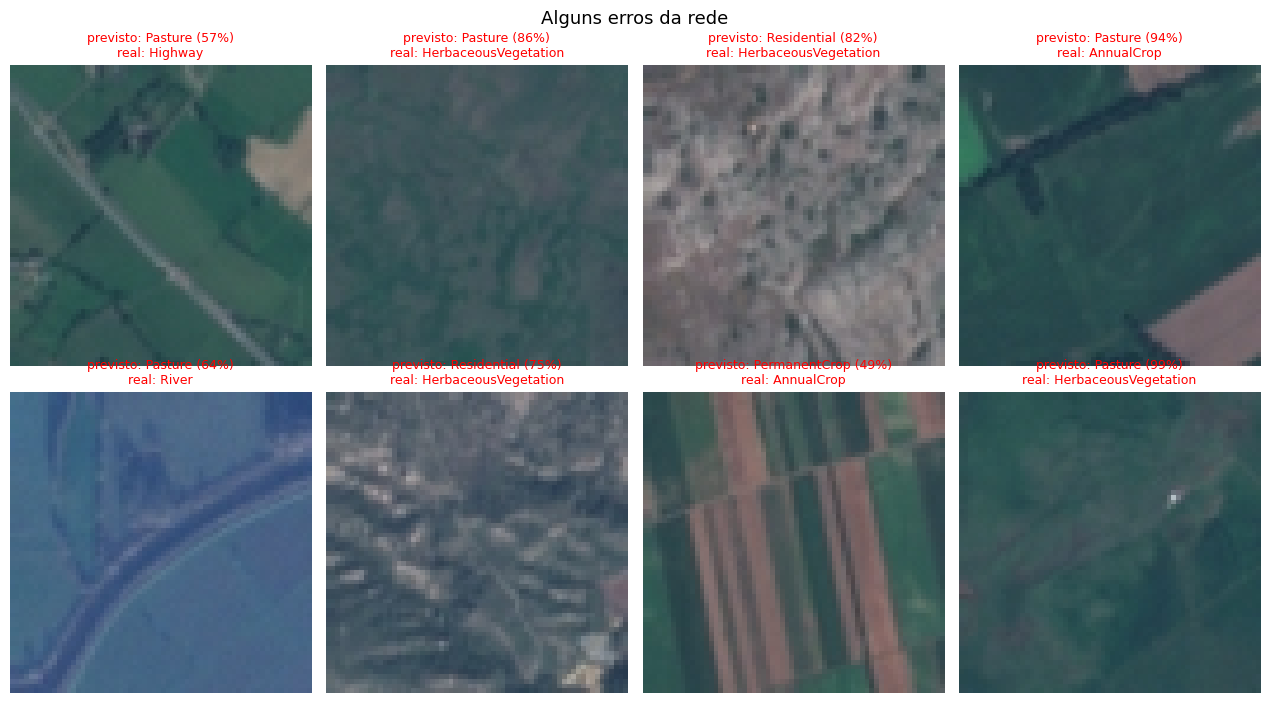

In [25]:
erros = np.where(y_pred != y_test)[0]
print(f"A rede errou {len(erros)} de {len(y_test)} imagens de teste.")
if len(erros) > 0:
    mostrar_grade(erros[:8], "Alguns erros da rede", 2, 4)

## 11. Comparação de topologias

Treinei a mesma pipeline com a mesma semente e os mesmos hiperparâmetros, mudando apenas a topologia
(número de blocos convolucionais e de filtros) e, ao final, a presença de BatchNorm e de Dropout.
Assim, a única diferença entre os modelos é a que implica-se medir.

| Modelo | Filtros por bloco | O que muda |
| --- | --- | --- |
| A | (16, 32) | rede menor e mais rasa (2 blocos) |
| B | (32, 64, 128) | base (3 blocos) |
| C | (32, 64, 128, 256) | mais profunda (4 blocos) |
| D | (64, 128, 256) | mais larga (dobro de filtros em 3 blocos) |
| E | (32, 64, 128), sem BatchNorm | efeito da BatchNorm |
| F | (32, 64, 128), sem Dropout | efeito do Dropout |

Comparada pela acurácia de validação e, no teste, pelo F1 macro. Como esta seção é só
uma comparação, o teste não é usado para escolher hiperparâmetros durante o treino.

In [27]:
EPOCHS_CMP = 15   # menos epocas que o treino principal, para a comparacao ser mais rapida

configs = {
    "A (16,32)":              dict(filters=(16, 32)),
    "B (32,64,128) base":     dict(filters=(32, 64, 128)),
    "C (32,64,128,256)":      dict(filters=(32, 64, 128, 256)),
    "D (64,128,256)":         dict(filters=(64, 128, 256)),
    "E base sem BatchNorm":   dict(filters=(32, 64, 128), batch_norm=False),
    "F base sem Dropout":     dict(filters=(32, 64, 128), dropout=0.0),
}

def avaliar(modelo):
    p = modelo.predict(test_ds, verbose=0)
    pred = p.argmax(axis=1)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    return accuracy_score(y_test, pred), prec, rec, f1

resultados, historicos = [], {}
for i, (nome, cfg) in enumerate(configs.items()):
    print(f"\n=== Treinando {nome} ===")
    set_random_seed(42)
    m = build_cnn(name=f"cnn_{i}", **cfg)
    compilar(m)
    t0 = time.time()
    h = treinar(m, EPOCHS_CMP, verbose=0)
    duracao = time.time() - t0
    acc, prec, rec, f1 = avaliar(m)
    historicos[nome] = h
    resultados.append({
        "Modelo": nome,
        "Parametros": m.count_params(),
        "Epocas treinadas": len(h.history["loss"]),
        "Acc treino": max(h.history["accuracy"]),
        "Acc validacao": max(h.history["val_accuracy"]),
        "Acc teste": acc,
        "Precision (macro)": prec,
        "Recall (macro)": rec,
        "F1 (macro)": f1,
        "Tempo (s)": round(duracao),
    })
    print(f"acc validacao = {resultados[-1]['Acc validacao']:.3f} | acc teste = {acc:.3f} | F1 macro = {f1:.3f} | {duracao:.0f}s")

tabela = pd.DataFrame(resultados).set_index("Modelo")
tabela.style.format({"Parametros": "{:,}", "Acc treino": "{:.3f}", "Acc validacao": "{:.3f}", "Acc teste": "{:.3f}",
                     "Precision (macro)": "{:.3f}", "Recall (macro)": "{:.3f}", "F1 (macro)": "{:.3f}"})


=== Treinando A (16,32) ===
acc validacao = 0.722 | acc teste = 0.737 | F1 macro = 0.724 | 69s

=== Treinando B (32,64,128) base ===
acc validacao = 0.827 | acc teste = 0.842 | F1 macro = 0.836 | 109s

=== Treinando C (32,64,128,256) ===
acc validacao = 0.888 | acc teste = 0.890 | F1 macro = 0.885 | 124s

=== Treinando D (64,128,256) ===
acc validacao = 0.782 | acc teste = 0.795 | F1 macro = 0.764 | 141s

=== Treinando E base sem BatchNorm ===
acc validacao = 0.763 | acc teste = 0.780 | F1 macro = 0.768 | 57s

=== Treinando F base sem Dropout ===
acc validacao = 0.877 | acc teste = 0.873 | F1 macro = 0.870 | 109s


,Parametros,Epocas treinadas,Acc treino,Acc validacao,Acc teste,Precision (macro),Recall (macro),F1 (macro),Tempo (s)
Modelo,,,,,,,,,
"A (16,32)","10,746",15,0.685,0.722,0.737,0.743,0.733,0.724,69
"B (32,64,128) base","111,722",15,0.849,0.827,0.842,0.846,0.841,0.836,109
"C (32,64,128,256)","424,042",15,0.905,0.888,0.890,0.900,0.886,0.885,124
"D (64,128,256)","406,346",11,0.839,0.782,0.795,0.806,0.784,0.764,141
E base sem BatchNorm,"111,050",15,0.768,0.763,0.780,0.776,0.775,0.768,57
F base sem Dropout,"111,722",15,0.923,0.877,0.873,0.880,0.875,0.870,109


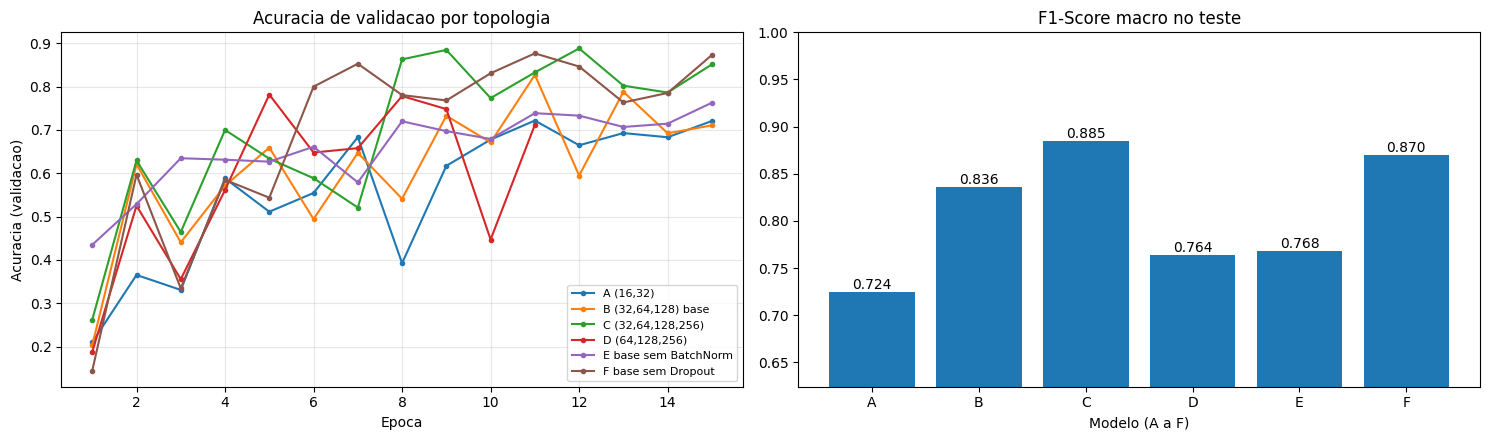

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

# Curvas de acuracia de validacao de todos os modelos
for nome, h in historicos.items():
    ax[0].plot(range(1, len(h.history["val_accuracy"]) + 1), h.history["val_accuracy"], marker=".", label=nome)
ax[0].set_title("Acuracia de validacao por topologia")
ax[0].set_xlabel("Epoca"); ax[0].set_ylabel("Acuracia (validacao)")
ax[0].legend(fontsize=8); ax[0].grid(True, alpha=0.3)

# F1 macro no teste
barras = ax[1].bar(range(len(tabela)), tabela["F1 (macro)"], color="tab:blue")
ax[1].bar_label(barras, fmt="%.3f")
ax[1].set_xticks(range(len(tabela)))
ax[1].set_xticklabels([n.split(" ")[0] for n in tabela.index])
ax[1].set_ylim(max(0, tabela["F1 (macro)"].min() - 0.1), 1)
ax[1].set_title("F1-Score macro no teste")
ax[1].set_xlabel("Modelo (A a F)")

plt.tight_layout(); plt.show()

## **12. Conclusões**

### **12.1. Desempenho da CNN Base**
- **Métricas Gerais:** O modelo base (3 blocos convolucionais com 32, 64 e 128 filtros) obteve um excelente desempenho, atingindo 90,67% de acurácia no conjunto de teste (F1-Score macro de **90,5%**).
- **Overfitting e Convergência:** O uso de *dropout* (0.4), *Batch Normalization* e técnicas de *data augmentation* foi crucial para regularizar o modelo. Analisando as curvas de aprendizado, o treino e a validação caminharam de forma estável e próxima. O `EarlyStopping` restaurou os melhores pesos na última época (época 30, com perda de validação mínima de **0.2616**).
- **Análise por Classe (Matriz de Confusão):**
  - **Melhores Classes:** As classes *Forest* (F1-Score: 97.8%) e *SeaLake* (F1-Score: 97.4%) obtiveram os melhores desempenhos devido às grandes massas de verde e azul escuro,respectivamente.
  - **Maiores Confusões (Piores F1-Scores):**
    - *PermanentCrop* (85.0%) e *HerbaceousVegetation* (88.3%) foram constantemente confundidas entre si ou com **AnnualCrop**, já que ambas compartilham padrões de vegetação rasteira, solo exposto e texturas agrícolas semelhantes sob a perspectiva de satélite.
    - Houve também uma confusão esperada entre **Highway (86.6%)** e **River (84.7%)**, motivada por ambas se apresentarem visualmente como linhas contínuas cruzando as imagens coloridas.
    - Os erros mostrados na seção 10 evidenciam que imagens com coberturas mistas (ex: uma estrada cruzando uma floresta) ou com resoluções limítrofes são as principais fontes de ambiguidade.

### **12.2. Comparação de Topologias (Seção 11)**
- **Impacto da Profundidade e Largura:**
  - Aumentar a profundidade para 4 blocos convolucionais (**Modelo C - 32,64,128,256**) trouxe o melhor resultado da rodada rápida, com **88,8% de acurácia de validação** e **88,5% de F1-Score macro no teste**, demonstrando que uma rede mais profunda extrai características espaciais mais complexas sem sobrecarregar severamente o tempo de processamento (~124s).
  - Dobrar a largura (**Modelo D - 64,128,256**) não resultou em ganhos proporcionais (obteve **78,2% de acurácia de validação**), mostrando que simplesmente adicionar filtros de forma indiscriminada pode inflar o custo computacional (~141s) sem garantir melhora.
- **Underfitting:** O **Modelo A (16,32)**, por ser muito raso, apresentou indícios claros de *underfitting*, estacionando em apenas **72,2%** de acurácia de validação.
- **Importância dos Componentes:**
  - **Sem BatchNorm (Modelo E):** Teve uma queda acentuada de desempenho (**76,3%** de acurácia de validação), além de apresentar maior instabilidade de gradientes e convergência mais lenta. Isso ratifica a importância da normalização em lote.
  - **Sem Dropout (Modelo F):** Embora tenha convergido rapidamente (atingindo **87,7%** na validação), o modelo sem Dropout perde o fator de regularização, tornando-o suscetível a overfitting severo se treinado por mais épocas.

### **12.3. Limitações e Próximos Passos**
- O dataset é limitado à região europeia e a imagens de 64x64 em RGB.
- Para evoluções futuras, sugere-se a exploração de modelos de *Transfer Learning* (como a MobileNetV2), utilização de pesos balanceados via `class_weight` e, idealmente, o uso do dataset multiespectral completo do EuroSAT (13 bandas) para aproveitar as assinaturas infravermelhas que facilitam a diferenciação de vegetação.